# MLP

In [71]:
import numpy as np
import matplotlib.pyplot as plt

In [72]:
# Sigmoid activation function, z = f(x)
def sigmoid(z):
  """Applies the sigmoid activation function"""
  return 1 / (1 + np.exp(-z))


# Derivative of the sigmoid activation function, y = f(x)
def sigmoid_derivative(y):
  """Computes the derivative of the sigmoid activation function"""
  return y * (1 - y)

In [73]:
# Forward Propagation
def forward_propagation(inputs, weights_input_hidden, weights_hidden_output):
  """Computes the output of the neural network"""

  # Step-1: Calculate input to hidden layer
  hidden_layer_input = np.dot(inputs, weights_input_hidden) # X.W1
  hidden_layer_output = sigmoid(hidden_layer_input) # Ha

  # Step-2: Calculate input to output layer
  output_layer_input = np.dot(hidden_layer_output, weights_hidden_output) # Ha.W2
  predicted_output = sigmoid(output_layer_input) # y_hat

  return hidden_layer_output, predicted_output

In [74]:
# Backpropagation
def backpropagation(inputs, targets, hidden_layer_output, predicted_output,
                    weights_input_hidden, weights_hidden_output, learning_rate):
  """Updates the weights of the neural network"""

  # Step-1: Calculate error at output layer
  error_output = targets - predicted_output

  # Step-2: Calculate the gradient (derivative) of the output layer
  gradient_output = error_output * sigmoid_derivative(predicted_output)

  # Step-3: Calculate error at hidden layer
  hidden_error = gradient_output.dot(weights_hidden_output.T)
  gradient_hidden = hidden_error * sigmoid_derivative(hidden_layer_output)

  # Step-4: Update the weights
  weights_hidden_output += hidden_layer_output.T.dot(gradient_output) * learning_rate
  weights_input_hidden += inputs.T.dot(gradient_hidden) * learning_rate

  return weights_input_hidden, weights_hidden_output


In [75]:
# Trainin inputs with bias
inputs = np.array([[1, 0, 0],
                   [1, 0, 1],
                   [1, 1, 0],
                   [1, 1, 1]])
targets = np.array([[0], [1], [1], [0]])
np.random.seed(42)

In [76]:
inputs.shape

(4, 3)

In [77]:
input_layer_neurons = inputs.shape[1]
hidden_layer_neurons = 4
output_layer_neurons = 1

# Learning rate
learning_rate = 0.3

epochs = 1500

In [78]:
# Initialize weights
weights_input_hidden = np.random.uniform(size=(input_layer_neurons, hidden_layer_neurons))
weights_hidden_output = np.random.uniform(size=(hidden_layer_neurons, output_layer_neurons))
weights_input_hidden.shape, weights_hidden_output.shape

((3, 4), (4, 1))

In [79]:
print(f"Initial Weights Input Hidden: {weights_input_hidden} \n Initial Weights Hidden Output: {weights_hidden_output}")

Initial Weights Input Hidden: [[0.37454012 0.95071431 0.73199394 0.59865848]
 [0.15601864 0.15599452 0.05808361 0.86617615]
 [0.60111501 0.70807258 0.02058449 0.96990985]] 
 Initial Weights Hidden Output: [[0.83244264]
 [0.21233911]
 [0.18182497]
 [0.18340451]]


In [80]:
# Training
# Store loss values
loss_history = []

for epoch in range(epochs):
  # Step-1: Perform FP
  hidden_layer_output, predicted_output = forward_propagation(inputs, weights_input_hidden, weights_hidden_output)
  # print(f"Epoch: {epoch+1}, Predicted Output: {predicted_output} \n Hidden Layer Output: {hidden_layer_output}")

  # Compute Mean Square Error (MSE)
  mse = np.mean(np.square(targets - predicted_output))
  loss_history.append(mse)
  print(f"Epoch: {epoch+1}, MSE: {mse}")

  # Step-2: Perform BP
  weights_input_hidden, weights_hidden_output = backpropagation(inputs, targets, hidden_layer_output, predicted_output,
                                                                weights_input_hidden, weights_hidden_output, learning_rate)
  # print(f"Epoch: {epoch+1}, Updated Weights Input Hidden: {weights_input_hidden} \n Updated Weights Hidden Output: {weights_hidden_output}")



Epoch: 1, MSE: 0.30245657014739824
Epoch: 2, MSE: 0.2920781865093287
Epoch: 3, MSE: 0.2829852183935221
Epoch: 4, MSE: 0.2753322958355225
Epoch: 5, MSE: 0.2691274508073617
Epoch: 6, MSE: 0.26425947587338144
Epoch: 7, MSE: 0.2605442668046876
Epoch: 8, MSE: 0.2577709603816631
Epoch: 9, MSE: 0.25573587044433843
Epoch: 10, MSE: 0.2542613859616939
Epoch: 11, MSE: 0.2532027497543178
Epoch: 12, MSE: 0.25244732001181686
Epoch: 13, MSE: 0.25191022664576995
Epoch: 14, MSE: 0.25152895331160807
Epoch: 15, MSE: 0.2512581754295781
Epoch: 16, MSE: 0.2510653977388424
Epoch: 17, MSE: 0.2509275055169687
Epoch: 18, MSE: 0.25082814756702654
Epoch: 19, MSE: 0.250755802289072
Epoch: 20, MSE: 0.25070237354113756
Epoch: 21, MSE: 0.25066218329551154
Epoch: 22, MSE: 0.25063125488355653
Epoch: 23, MSE: 0.2506068059038276
Epoch: 24, MSE: 0.2505868908880501
Epoch: 25, MSE: 0.25057015019900747
Epoch: 26, MSE: 0.250555633925035
Epoch: 27, MSE: 0.25054267854342605
Epoch: 28, MSE: 0.25053082062607435
Epoch: 29, MSE: 0.

In [81]:
print("Final output after training: ")
print(predicted_output)

Final output after training: 
[[0.08382651]
 [0.7989323 ]
 [0.81381121]
 [0.24108728]]


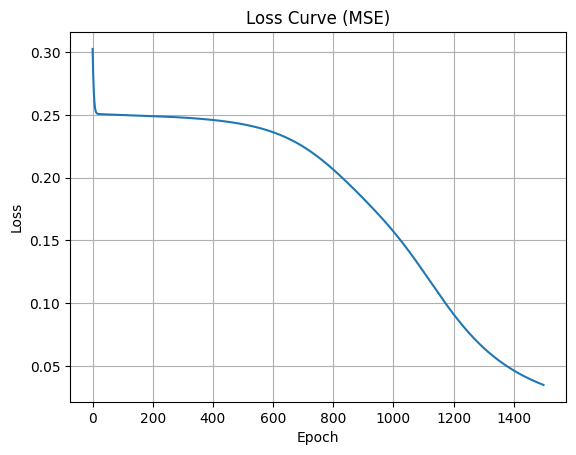

In [82]:
# Plot loss curve
plt.plot(loss_history)
plt.title("Loss Curve (MSE)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.show()